# **AlexNet**

* 원본 AlexNet은 224x224 입력을 가정하고 11x11, stride=4 같은 큰 커널을 사용한다.

* CIFAR-10은 32x32라서 그대로 쓰면 특징맵 크기가 중간에 0 이하로 떨어져버린다.

* 그래서 우리가 할 프로젝트는 커널을 3x3으로 줄이고 stride=1, padding=1을 사용한다. (Mini-AlexNet)

##**AlexNet 구조 설명**
- 출처 : http://proceedings.neurips.cc/paper_files/paper/2012/file/c399862d3b9d6b76c8436e924a68c45b-Paper.pdf

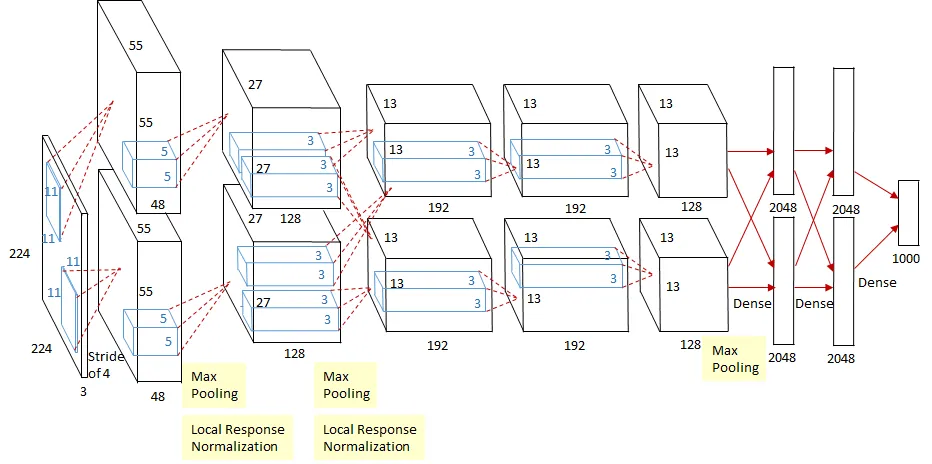

## **환경설정**

이미지 학습은 CPU에서 굉장히 느리다.
- 오늘 내에 끝내고싶다면 GPU를 사용하자.

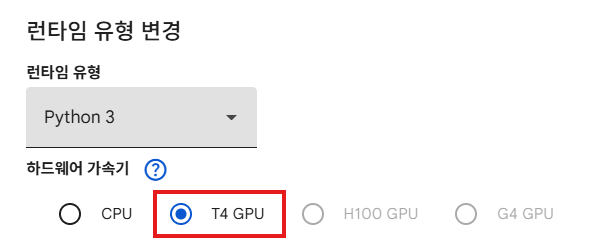

## **1. data 준비하기**

CIFAR-10 데이터셋을 사용한다.
- 이미지는 3(채널) x 32 x 32이다.

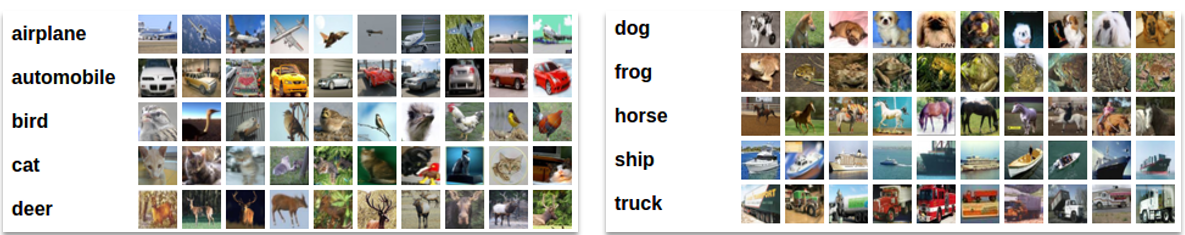

**CIFAR10 데이터 로드 및 정규화**

- 아래 코드를 실행시켜보며 코드를 이해해보도록 합시다.

In [ ]:
import torch
import torchvision
from torchvision.transforms import v2

In [ ]:
# CUDA 사용 가능하면 GPU, 아니면 CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

device: cuda
GPU: Tesla T4


**Q1. Data는 Kaggle에서 다운로드해서 활용한다.**

아래 코드를 실행하여 데이터를 다운로드받고 정규화하여 학습 데이터로 준비한다.

In [ ]:
import kagglehub
path = kagglehub.dataset_download("oxcdcd/cifar10")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cifar10' dataset.
Path to dataset files: /kaggle/input/cifar10


**Q2. 다운로드 받은 데이터의 구성을 확인한다.**
- test 이미지 : 1000장씩 10클래스 (10000개)
- train 이미지 : 5000장씩 10클래스 (50000개)

In [ ]:
import os
for root, dirs, files in os.walk(path):
    print(root, len(files), "files")

/kaggle/input/cifar10 1 files
/kaggle/input/cifar10/cifar10 1 files
/kaggle/input/cifar10/cifar10/test 0 files
/kaggle/input/cifar10/cifar10/test/airplane 1000 files
/kaggle/input/cifar10/cifar10/test/horse 1000 files
/kaggle/input/cifar10/cifar10/test/truck 1000 files
/kaggle/input/cifar10/cifar10/test/automobile 1000 files
/kaggle/input/cifar10/cifar10/test/ship 1000 files
/kaggle/input/cifar10/cifar10/test/dog 1000 files
/kaggle/input/cifar10/cifar10/test/bird 1000 files
/kaggle/input/cifar10/cifar10/test/frog 1000 files
/kaggle/input/cifar10/cifar10/test/cat 1000 files
/kaggle/input/cifar10/cifar10/test/deer 1000 files
/kaggle/input/cifar10/cifar10/train 0 files
/kaggle/input/cifar10/cifar10/train/airplane 5000 files
/kaggle/input/cifar10/cifar10/train/horse 5000 files
/kaggle/input/cifar10/cifar10/train/truck 5000 files
/kaggle/input/cifar10/cifar10/train/automobile 5000 files
/kaggle/input/cifar10/cifar10/train/ship 5000 files
/kaggle/input/cifar10/cifar10/train/dog 5000 files
/k

**Q3. 이미지를 전처리한다.**

In [ ]:
transform = v2.Compose([
    v2.ToImage(),                                     # 이미지를 → PyTorch 텐서로 변환
    v2.ToDtype(torch.float32, scale=True),            # 정수(0~255) → 실수(0~1)로 변환
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))     # 0~1 → -1~1 범위로 정규화 (학습 안정화)
])

In [ ]:
from torchvision.datasets import ImageFolder
path = "/kaggle/input/cifar10/cifar10/"
trainset = ImageFolder(root=f"{path}/train", transform=transform)
testset = ImageFolder(root=f"{path}/test", transform=transform)
classes = trainset.classes

**Q4. batch로 학습시키기위해 DataLoader를 활용하여 학습에 쓸 형태로 변환한다.**
- AlexNet은 Batch 크기를 128로 진행했다.

In [ ]:
batch_size=128

# num_workers : 2개의 프로세스가 병렬처리
# pin_memory :  CPU -> GPU로 데이터를 옮기는 속도를 향상

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True,
    num_workers=2, pin_memory=True
)

testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=True
)

**Q6. 첫번째 batch를 시각화해보자.**

- 아래 코드는 오류가 날 수 있습니다.
- data loader로 탑재한 데이터의 이름을 확인해 주세요.

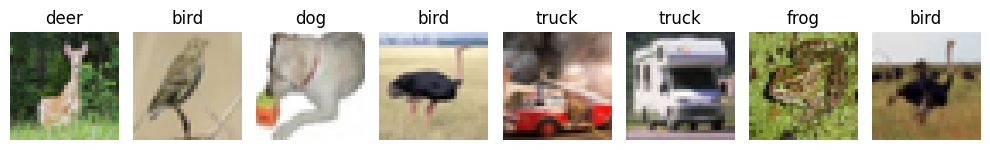

In [ ]:
import matplotlib.pyplot as plt

dataiter = iter(trainloader)
images, labels = next(dataiter)

fig, axes = plt.subplots(1, 8, figsize=(10, 2))

for j in range(8):
    img = images[j] / 2 + 0.5        # unnormalize (-1~1 → 0~1)
    img = img.permute(1, 2, 0)       # (C,H,W) → (H,W,C)
    axes[j].imshow(img)
    axes[j].set_title(classes[labels[j]])
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## **2. Mini-AlexNet 정의하기**

원본 AlexNet의 conv 5개 + FC 3개, ReLU, MaxPool, Dropout 등 주요내용은 유지하되 CIFAR-10(32x32)에 맞게 커널 크기와 stride를 줄인 버전이다.

| 레이어 | 연산 | 출력 shape |
|---|---|---|
| 입력 | - | 3x32x32 |
| Conv1 | 3x3, 64개, pad1 + ReLU + MaxPool2 | 64x16x16 |
| Conv2 | 3x3, 192개, pad1 + ReLU + MaxPool2 | 192x8x8 |
| Conv3 | 3x3, 384개, pad1 + ReLU | 384x8x8 |
| Conv4 | 3x3, 256개, pad1 + ReLU | 256x8x8 |
| Conv5 | 3x3, 256개, pad1 + ReLU + MaxPool2 | 256x4x4 |
| FC1 | Linear(4096, 1024) + ReLU + Dropout | 1024 |
| FC2 | Linear(1024, 512) + ReLU + Dropout | 512 |
| FC3 | Linear(512, 10) | 10 (클래스 수) |

- dropout은 절반 (0.5)을 드랍하도록 한다.

**Q1. 위 레이어 구성을 참고하여 신경망을 구현하라.**

In [ ]:
# code here

**Q2. 신경망 인스턴스를 생성하고 출력하여 레이어 상태를 확인하자.**

- 신경망 모델을 device로 옮기는것을 잊지 말자.

In [ ]:
# code here

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=4096, out_features=1024, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=1024, out_features=512, bias=Tr

## **3. 모델 학습**

**Q1. 손실함수와 옵티마이저를 정의하라.**
- Loss : CrossEntropyLoss (다중 분류)
- optimizer : SGD (learning rate:0.01, momentum:0.9, weight decay : 0.0005)

In [ ]:
# code here

**Q2. 모델을 학습시킨다.**
- epoch : 20

AlexNet은 90번 내로 수렴했다고 한다.
- 하지만 실제 AlexNet은 224 x 224 크기의 이미지를 사용했다.
- 그러니 약 7배정도 차이가 나니, 20번 내로 수렴할것으로 예상된다.
- 데이터를 device (GPU)로 옮기는 것을 잊지 말자.

데이터가 많으므로 시간이 오래 걸릴 수 있다.

In [ ]:
# code here

epoch  1/30 | avg loss 2.2992
epoch  2/30 | avg loss 1.8938
epoch  3/30 | avg loss 1.5532
epoch  4/30 | avg loss 1.3566
epoch  5/30 | avg loss 1.2102
epoch  6/30 | avg loss 1.0804
epoch  7/30 | avg loss 0.9523
epoch  8/30 | avg loss 0.8532
epoch  9/30 | avg loss 0.7795
epoch 10/30 | avg loss 0.7135
epoch 11/30 | avg loss 0.6527
epoch 12/30 | avg loss 0.6007
epoch 13/30 | avg loss 0.5513
epoch 14/30 | avg loss 0.5041
epoch 15/30 | avg loss 0.4674
epoch 16/30 | avg loss 0.4278
epoch 17/30 | avg loss 0.3862
epoch 18/30 | avg loss 0.3512
epoch 19/30 | avg loss 0.3130
epoch 20/30 | avg loss 0.2853
epoch 21/30 | avg loss 0.2554
epoch 22/30 | avg loss 0.2251
epoch 23/30 | avg loss 0.2089
epoch 24/30 | avg loss 0.1752
epoch 25/30 | avg loss 0.1574
epoch 26/30 | avg loss 0.1394
epoch 27/30 | avg loss 0.1232
epoch 28/30 | avg loss 0.1144
epoch 29/30 | avg loss 0.0980
epoch 30/30 | avg loss 0.0923


## **4. 모델 저장**

**Q1. Path를 설정하고, 모델의 가중치를 저장한다.**
```
PATH = './alexnet.pt'
torch.save(net.state_dict(), PATH)
```

그리고 해당 파일을 다운로드해두도록 한다.

In [ ]:
# code here

## **5. 모델 불러오기**

**Q1. 모델을 불러오자.**

모델을 불러올 때에는, 먼저 같은 구조의 신경망을 만들고, 가중치만 덮어씌워주는식이다.

```
net = AlexNet(num_classes=10).to(device)
net.load_state_dict(torch.load(PATH, map_location=device))
```

In [ ]:
# code here

<All keys matched successfully>

## **6. 모델 평가**

**Q1.test data를 활용하여 모델의 정확도를 출력해보자.**

In [ ]:
# code here

test accuracy: 82.47% (8247/10000)


**Q2. 클래스별 정확도를 확인해보자.**

- 아래 코드는 오류가 발생할 수 있습니다. 모델명과 data lodader들의 이름을 확인해주세요.

In [ ]:
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

net.eval()
with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = net(images)
        _, predictions = torch.max(outputs, 1)

        for label, prediction in zip(labels, predictions):
            label_idx = label.item()
            pred_idx = prediction.item()
            if label_idx == pred_idx:
                correct_pred[classes[label_idx]] += 1
            total_pred[classes[label_idx]] += 1

for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: airplane is 85.0 %
Accuracy for class: automobile is 88.3 %
Accuracy for class: bird  is 74.2 %
Accuracy for class: cat   is 71.9 %
Accuracy for class: deer  is 85.4 %
Accuracy for class: dog   is 70.4 %
Accuracy for class: frog  is 84.8 %
Accuracy for class: horse is 85.9 %
Accuracy for class: ship  is 89.3 %
Accuracy for class: truck is 89.5 %


**Q3. 테스트 데이터의 첫 10개만 가져와서 이미지를 분류하고 시각화해보자.**

- 아래 코드는 오류가 발생할 수 있습니다. 모델명과 data lodader들의 이름을 확인해주세요.

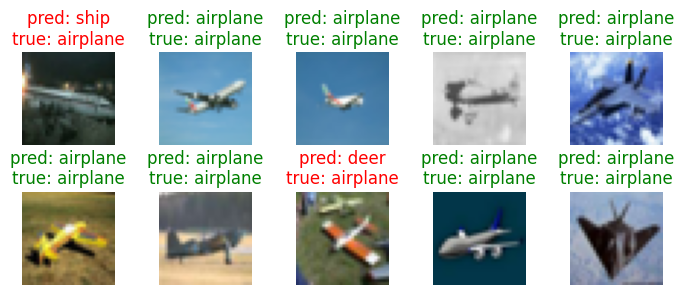

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

n = 10
# 테스트 데이터 10개 가져오기
images, labels = next(iter(testloader))
images = images[:n]
labels = labels[:n]

# GPU에서 예측
net.eval()
with torch.no_grad():
    outputs = net(images.to(device, non_blocking=True))
    predicted = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(7, 3))

for i, ax in enumerate(axes.flat):

    # CIFAR-10 이미지 역정규화
    img = images[i].cpu()
    img = img / 2 + 0.5

    # (C, H, W) -> (H, W, C)
    img = img.permute(1, 2, 0).numpy()

    true_label = labels[i].item()
    pred_label = predicted[i].item()

    ax.imshow(img)
    color = "green" if pred_label == true_label else "red"
    ax.set_title(
        f"pred: {classes[pred_label]}\ntrue: {classes[true_label]}",
        color=color
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

##**7. 내 이미지**

**Q1. 클래스에 해당되는 이미지를 하나 다운로드 합니다.**

- 해당 이미지를 업로드하고, 아래 코드를 순차적으로 실행시켜 결과를 확인합니다.

In [ ]:
from PIL import Image
import torchvision.transforms as transforms

img = Image.open('cat.jpg')

In [ ]:
img = img.resize([32, 32])

In [ ]:
my_test = transform(img)
my_test.shape

torch.Size([3, 32, 32])

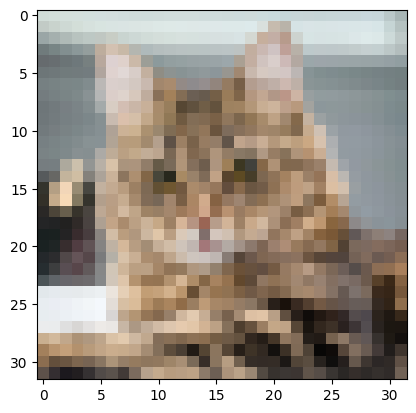

In [ ]:
img_show = my_test.permute(1, 2, 0)
img_show = img_show * 0.5 + 0.5
plt.imshow(img_show)
plt.show()

In [ ]:
# code here